# DHT Propagation vs. Analytic Gaussian Beam (Free Space + Through a Lens)

Validates the Discrete Hankel Transform (DHT) propagation machinery — the same `DHTarrays`/`DHTtransformMatrix`/propagate approach used throughout `common/` and `without_zernike/` — against the closed-form paraxial Gaussian-beam solution, in two stages:

1. **Free space**: propagates a Gaussian beam via the DHT across a range of z and fits the resulting radial profile to extract the beam waist, comparing against the analytic Gaussian beam waist `w(z) = w0*sqrt(1+(z/zR)^2)`.
2. **Through an ideal thin lens**: reflects/refocuses the beam and compares the DHT-propagated waist evolution after the lens to the analytic thin-lens Gaussian transformation (`lens_w`, `lens_R`), including a plot of waist vs. z before/after the lens with the expected focus location marked.

This is the fullest independent validation of the DHT propagation machinery against a known closed-form solution in either repo — nothing in current tested code re-validates `propagate()` this way, which is why it's being kept.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import jv
from scipy.optimize import curve_fit
import math

font = {'size'   : 28}

plt.rc('font', **font)
plt.rcParams['figure.figsize'] = (16,9)

In [2]:
def DHTarrays(N,R,ell):
    Zeroes=np.genfromtxt('BesselZeroes'+str(ell)+'.csv')
    r=R*Zeroes[:N]/Zeroes[N-1]
    k=Zeroes[:N]/R
    return np.array([r,k])

In [3]:
def DHTtransformMatrix(N,R,ell):
    Zeroes=np.genfromtxt('BesselZeroes'+str(ell)+'.csv')
    alpha=Zeroes[:N]
    kR = alpha[N-1]
    kmax = kR/R;
    T = jv(ell,np.outer(alpha,alpha)/kR) / np.outer( abs(jv(ell+1,alpha)),abs(jv(ell+1,alpha)) ) / kR;
    #print(T)
    A = abs(jv(ell+1,alpha));
    T_R2K = 4.0*np.pi*(R/kmax)*T * A[:, None] / A[None,:] 
    T_K2R = (1/np.pi)*(kmax/R)*T * A[:, None] / A[None,:] 

    return T_R2K,T_K2R

In [4]:
def w(z,zR,w0):
    return w0*np.sqrt((1+(z/zR)**2))

In [5]:
def R(z,zR):
    return (z**2+zR**2)/z

In [6]:
def gauss(r,z,zR,k0,w0,lens=False):
    amp=(w0/w(z,zR,w0))*np.exp(-(r/w(z,zR,w0))**2)
    longitudinal=np.exp(1j*(k0*z-np.arctan(z/zR)))
    radial=1 if z==0 else np.exp(1j*k0*r**2/(2*R(z,zR)))
    return amp*longitudinal*radial

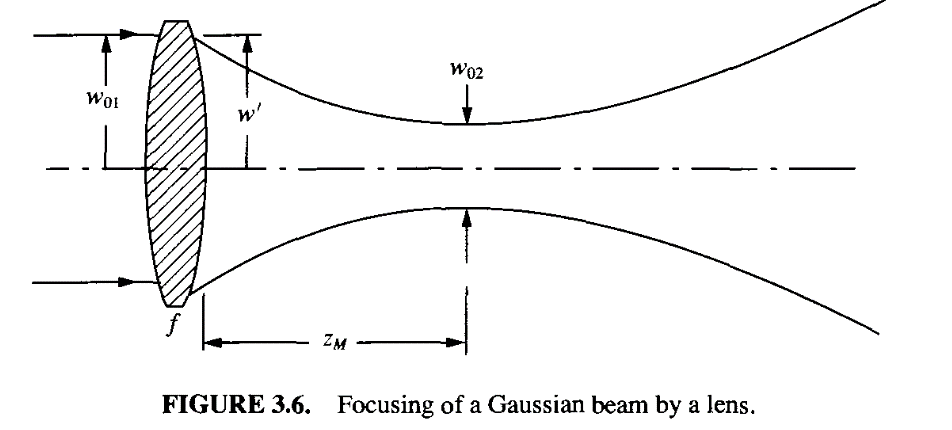

In [7]:
def f(r, a, w0sq):
    return a*np.exp(-r**2/w0sq)

In [8]:
def find_waist(r,g,p0):    
    popt,pcov=curve_fit(f,r,g,p0)
    return popt[1],np.sqrt(np.diag(pcov))[1]

In [9]:
def lens_R(f,z,w0sq,wavelength=1e-6):
    z01=np.pi*w0sq/wavelength
    
    numerator = (1-z/f)**2 +(z/z01)**2
    denominator= -1/f +z*(1/(f**2)+1/(z01**2))
    return numerator/denominator

In [10]:
def lens_w(f,z,w0sq,wavelength=1e-6):
    z01=np.pi*w0sq/wavelength

    numerator = (1-z/f)**2 +(z/z01)**2
    denominator=(1/z01)
    return np.sqrt(wavelength/np.pi * numerator/denominator)

In [11]:
def zM(f,wsq,wavelength=1e-6):
    z01=np.pi*wsq/wavelength

    return f/(1+(f/z01)**2)

In [12]:
def lens_gauss(r,f,z,zR,k0,w0,w0sq,lens=False):
    amp=(w0/lens_w(f,z,w0sq))*np.exp(-(r/lens_w(f,z,w0sq))**2)
    longitudinal=np.exp(1j*(k0*z-np.arctan(z/zR)))
    radial=1 if z==0 else np.exp(1j*k0*r**2/(2*lens_R(f,z,w0sq)))
    #radial=1
    return amp*longitudinal*radial

# Parameters

In [13]:
k0=2*np.pi/(1e-6)
nr=500
w0=3e-4
rmax=1.5e-3
zR=np.pi*w0**2/(1e-6)
zI=0.1*zR
zF=0.1
OoM=math.floor(math.log(w0**2, 10))
w_guess=10**OoM
print(zR)

0.28274333882308134


In [14]:
[r,k] = DHTarrays(nr,rmax,0)

zi=np.linspace(0,zI,101)
zf=np.linspace(0,zF,5001)

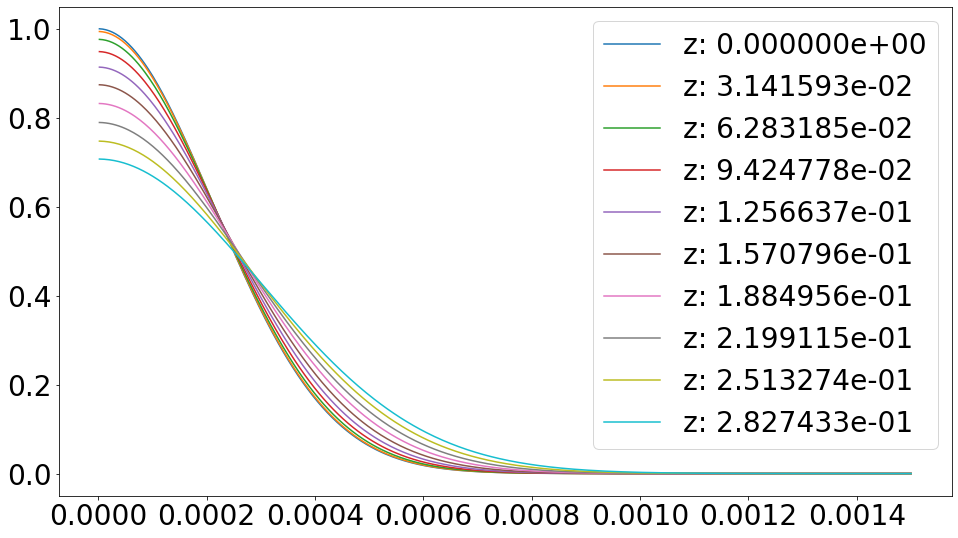

In [15]:
#print(find_waist(r,g0))
for z in np.linspace(0,zR,10):
    g=np.abs(gauss(r,z,zR,k0,w0))
    plt.plot(r,g,label='z: %e'%(z))
plt.legend()
plt.show()

-1.0471134616299679e-16


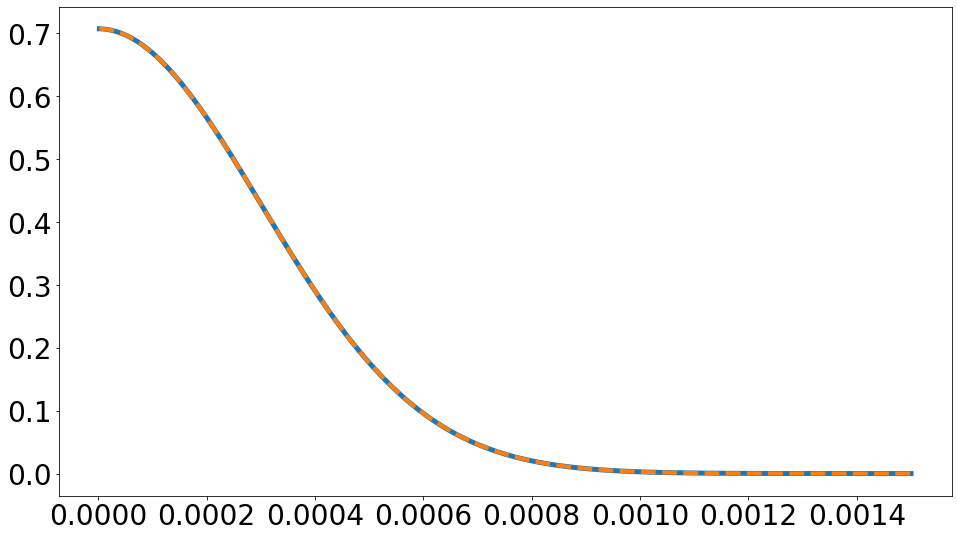

In [16]:
g0=gauss(r,0,zR,k0,w0)
gi=gauss(r,zR,zR,k0,w0)
popt,pcov=curve_fit(f,r,np.abs(gi),[1,w_guess])
plt.plot(r,np.abs(gi),linewidth=5,label=('original'))
cf=f(r,popt[0],popt[1])
plt.plot(r,np.abs(cf),linestyle='--',linewidth=4,label='curvefit')
print(np.sum(np.abs(gi)**2-np.abs(cf)**2)/np.sum(np.abs(gi)**2))
plt.show()

In [17]:
waist=[]
for z in zi:
    g=np.abs(gauss(r,z,zR,k0,w0))
    wst,cw0=find_waist(r,g,[1,w_guess])
    if cw0 < 1e-6:
        waist.append(wst)
    else:
        print("z: %.3e \t cov:%.3e "%(z,cw0)) 

9.089999999999999e-08


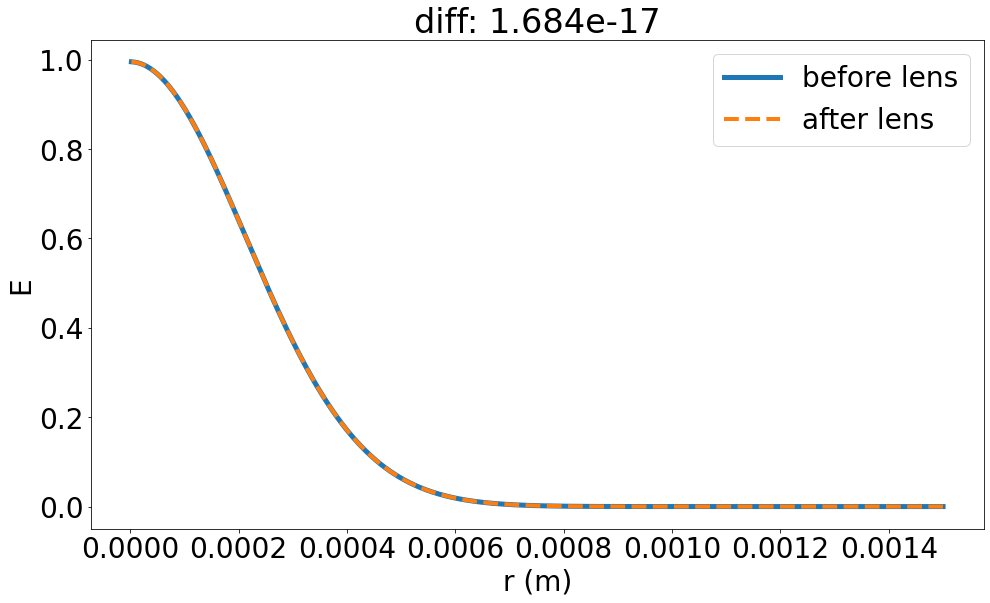

In [18]:
g_bef=np.abs(gauss(r,zI,zR,k0,w0))
w01=waist[-1]
print(w01)
g_aft=np.abs(lens_gauss(r,0.05625,0,zR,k0,w0,w01))
plt.plot(r,np.abs(g_bef),linewidth=5,label="before lens")
plt.plot(r,np.abs(g_aft),linewidth=4,linestyle='--',label="after lens")
diff=np.abs(np.sum(np.abs(g_bef)**2-np.abs(g_aft)**2)/np.sum(np.abs(g_bef)**2))
plt.title('diff: %.3e'%diff)

plt.xlabel('r (m)')
plt.ylabel('E')
plt.legend()
plt.savefig("gauss_bf_af")
plt.show()

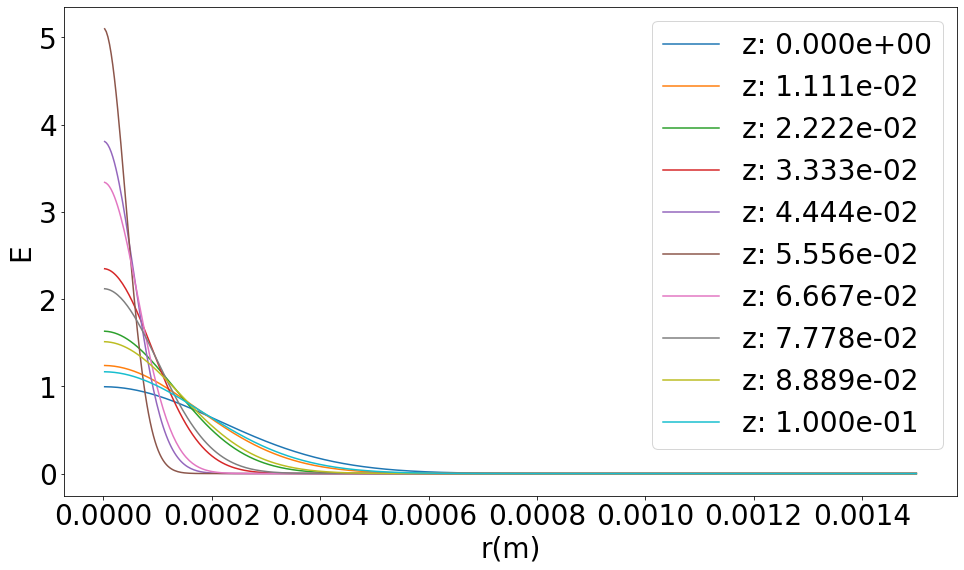

In [19]:
#print(find_waist(r,g0))
w01=waist[-1]
for z in np.linspace(0,zF,10):
    g=np.abs(lens_gauss(r,0.05625,z,zR,k0,w0,w01))
    plt.plot(r,g,label='z: %.3e'%(z))
plt.xlabel('r(m)')
plt.ylabel('E')
plt.legend()
plt.savefig('after_lens_gauss')
plt.show()

In [20]:
zM(0.05625,waist[-1])

0.05414908415101411

In [21]:
aflens=[]
w01=waist[-1]
for z in zf:
    g=np.abs(lens_gauss(r,0.05625,z,zR,k0,w0,w01))
    wst,cw0=find_waist(r,g,[1,w_guess])
    if cw0 < 1e-6:
        aflens.append(wst)
    else:
        print("z: %.3e \t cov:%.3e "%(z,cw0)) 

<ipython-input-7-a16732c32586>:2: RuntimeWarning: overflow encountered in exp
  return a*np.exp(-r**2/w0sq)
<ipython-input-7-a16732c32586>:2: RuntimeWarning: overflow encountered in multiply
  return a*np.exp(-r**2/w0sq)


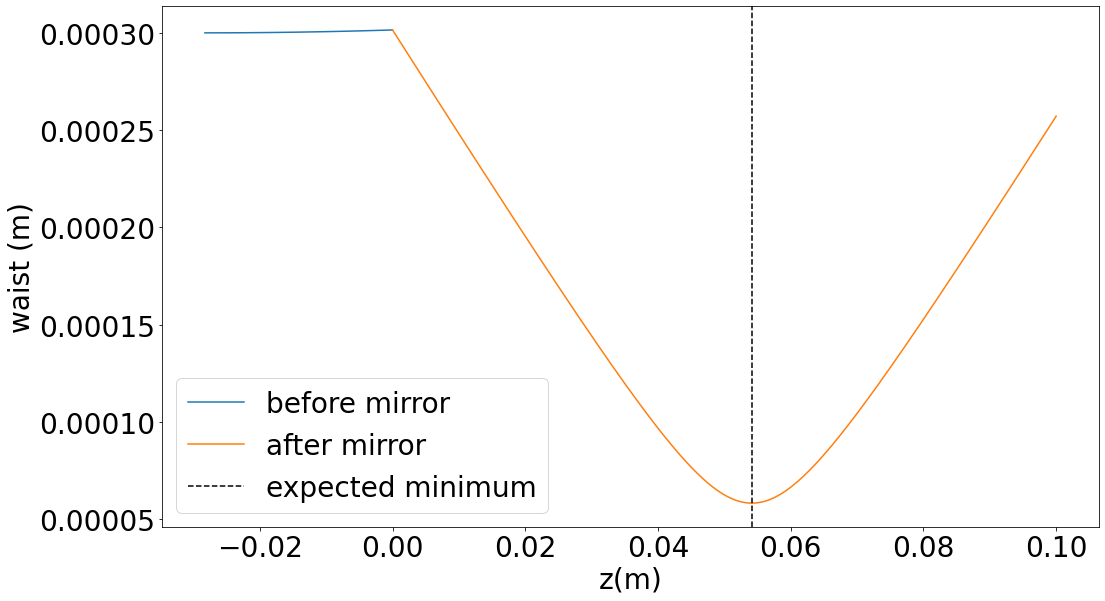

In [22]:
plt.plot(zi-zi[-1],np.sqrt(waist),label="before mirror")
plt.plot(zf,np.sqrt(aflens),label='after mirror')
plt.axvline(x=zM(0.05625,waist[-1]), color='k', linestyle='--', label="expected minimum")

plt.ylabel("waist (m)")
plt.xlabel("z(m)")
plt.legend()
plt.tight_layout()
plt.savefig("gaussian_lens_waist")
plt.show()

In [23]:
print(zf[np.argmin(aflens)])

0.05414000000000001


In [24]:
aflens[-1]

6.613533373403058e-08

In [25]:
np.sqrt(w01)

0.0003014962686336267